In [1]:
#%pip install pyobis
#%pip install pyarrow
#%pip install geopandas
#%pip install dask[dataframe]
#%pip install osgeo
#%pip install chardet
#%pip install openpyxl

In [2]:
import os
import pandas as pd
from tqdm import tqdm
import pyarrow as pa
import pyarrow.parquet as pq
import glob
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import re
import unicodedata
import requests
import geopandas as gpd
from shapely.geometry import Point
import xml.etree.ElementTree as ET
import dask.dataframe as dd
import csv
import chardet
import rasterio 
import geopandas as gpd
import numpy as np
from rasterio.transform import from_bounds
from fastparquet import ParquetFile
from datetime import datetime
import time
import pyobis
import openpyxl

os.chdir ('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\OBIS')

## Check column types

In [3]:
# Load the Parquet file
file_path = "merged_filtered.parquet"
df = pd.read_parquet(file_path)
# Display basic information about the dataset
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
# Display column names and data types
print("Column names and data types:")
print(df.dtypes)
# Save column names and data types to a CSV file
output_csv = "column_data_types.csv"  # Specify the output CSV file name
column_info = pd.DataFrame({
    "Column Name": df.dtypes.index,  # Column names
    "Data Type": df.dtypes.values    # Corresponding data types
})
# Save the column information to a CSV file
column_info.to_csv(output_csv, index=False)
print(f"Column names and data types saved to {output_csv}")
# Calculate coverage (percentage of non-missing values) for each column
coverage = (df.notnull().sum() / len(df)) * 100  # Calculate percentage of non-missing values
coverage_df = pd.DataFrame({
    "Column Name": coverage.index,  # Column names
    "Coverage (%)": coverage.values  # Corresponding coverage percentages
})
# Display coverage information
print("Coverage (percentage of non-missing values) for each column:")
print(coverage_df)
# Save coverage information to a CSV file
coverage_csv = "column_coverage.csv"  # Specify the output CSV file name
coverage_df.to_csv(coverage_csv, index=False)
print(f"Coverage information saved to {coverage_csv}")

Number of rows: 642300
Number of columns: 227
Column names and data types:
basisOfRecord                str
brackish                  object
catalogNumber                str
class                        str
classid                  float64
                          ...   
roundedLongitude             str
unique_id                    str
associatedOccurrences        str
identifiedByID               str
vitality                     str
Length: 227, dtype: object
Column names and data types saved to column_data_types.csv
Coverage (percentage of non-missing values) for each column:
               Column Name  Coverage (%)
0            basisOfRecord    100.000000
1                 brackish     77.541803
2            catalogNumber     38.810680
3                    class     92.460532
4                  classid     92.460532
..                     ...           ...
222       roundedLongitude    100.000000
223              unique_id    100.000000
224  associatedOccurrences      0.050911
225  

# Data cleaning

## Filter out stations on land based on bathymetry

In [4]:
# Step 1: Load the Parquet file
input_file = "merged_filtered.parquet"
df = pd.read_parquet(input_file)
# Step 2: Extract unique station locations along with the year column
unique_stations = df[['decimalLatitude', 'decimalLongitude']].drop_duplicates()
# Step 3: Save the result to a new file
output_file = "unique_coordinates.parquet"
unique_stations.to_parquet(output_file, index=False)
# Optional: Save as CSV if needed
unique_stations.to_csv("unique_coordinates.csv", index=False)
print(f"Unique station locations with year saved to {output_file}")

Unique station locations with year saved to unique_coordinates.parquet


In [5]:
def extract_raster_values(raster_path, coordinates_df, batch_size=10000):
    """
    Extract raster values for given coordinates from a single raster file.
    Parameters:
        raster_path (str): Path to the merged raster file.
        coordinates_df (pd.DataFrame): DataFrame with 'decimalLatitude' and 'decimalLongitude'.
        batch_size (int): Number of points to process in each batch.
    Returns:
        pd.DataFrame: DataFrame with extracted raster values.
    """
    results = []
    total_batches = len(coordinates_df) // batch_size + (1 if len(coordinates_df) % batch_size != 0 else 0)
    with rasterio.open(raster_path) as src:
        bounds = src.bounds  # Get raster bounds
        with tqdm(total=total_batches, desc="Processing Batches", unit="batch") as pbar:
            for i in range(0, len(coordinates_df), batch_size):
                batch = coordinates_df.iloc[i:i + batch_size].copy()
                batch.loc[:, 'gebco'] = np.nan  # Initialize the column for raster values
                # Adjust longitudes at the antimeridian
                batch['decimalLongitude'] = batch['decimalLongitude'].apply(
                    lambda lon: -180 if lon == 180 else lon
                )
                # Filter coordinates within the raster bounds
                batch_in_bounds = batch[
                    (batch['decimalLongitude'] >= bounds.left) &
                    (batch['decimalLongitude'] <= bounds.right) &
                    (batch['decimalLatitude'] >= bounds.bottom) &
                    (batch['decimalLatitude'] <= bounds.top)
                ]
                # Extract raster values for these coordinates
                coords = [(lon, lat) for lon, lat in zip(batch_in_bounds['decimalLongitude'], batch_in_bounds['decimalLatitude'])]
                values = list(src.sample(coords))
                # Assign values to the batch DataFrame
                for idx, value in zip(batch_in_bounds.index, values):
                    if value[0] is not None and not np.isnan(value[0]):
                        batch.loc[idx, 'gebco'] = value[0]
                results.append(batch)
                pbar.update(1)
    return pd.concat(results, ignore_index=True)
# File path to the merged raster
raster_file = r"..\GEBCO\gebco_merged.tif"
# Load the unique_coordinates.parquet file
coordinates = pd.read_parquet("unique_coordinates.parquet")
# Ensure decimalLongitude and decimalLatitude are numeric
coordinates['decimalLongitude'] = pd.to_numeric(coordinates['decimalLongitude'], errors='coerce')
coordinates['decimalLatitude'] = pd.to_numeric(coordinates['decimalLatitude'], errors='coerce')
# Drop rows with invalid (NaN) coordinates
coordinates = coordinates.dropna(subset=['decimalLongitude', 'decimalLatitude'])
# Extract raster values
result_df = extract_raster_values(raster_file, coordinates)
# Save the results to a Parquet file
result_df.to_parquet("gebco_values.parquet", index=False)
# Save the results to a CSV file
result_df.to_csv("gebco_values.csv", index=False)
print("Results saved as 'gebco_values.parquet' and 'gebco_values.csv'.")

Processing Batches: 100%|██████████| 6/6 [00:06<00:00,  1.12s/batch]


Results saved as 'gebco_values.parquet' and 'gebco_values.csv'.


## Apply filter (remove records above zero)

In [6]:
# Load the Parquet file
coordinates = pd.read_parquet("gebco_values.parquet")
# Filter out stations with 'gebco' values above zero
filtered_coordinates = coordinates[coordinates['gebco'] <= 0]
# Save the filtered DataFrame to a new Parquet file
filtered_coordinates.to_parquet("gebco_filtered.parquet", index=False)
# Save the filtered DataFrame to a new CSV file
filtered_coordinates.to_csv("gebco_filtered.csv", index=False)
print("Filtered results saved as 'gebco_filtered.parquet' and 'gebco_filtered.csv'.")

Filtered results saved as 'gebco_filtered.parquet' and 'gebco_filtered.csv'.


In [7]:
# File paths
filtered_coordinates_file = "gebco_filtered.parquet"
gbif_file = "merged_filtered.parquet"
output_file = "obis_filtered_dataset_marine.parquet"
# Load the filtered coordinates (from gebco_values_filtered.parquet)
filtered_coordinates = pd.read_parquet(filtered_coordinates_file)
# Extract unique coordinate pairs and their corresponding 'gebco' values
filtered_coords_with_gebco = filtered_coordinates[['decimalLongitude', 'decimalLatitude', 'gebco']]
# Convert to a set for fast filtering
filtered_coords_set = set(zip(filtered_coords_with_gebco['decimalLongitude'], filtered_coords_with_gebco['decimalLatitude']))
# Define a function to filter a chunk and add the 'gebcoDepth' column
def filter_and_add_gebco(chunk, coords_with_gebco):
    """
    Filter a chunk of the GBIF dataset and add the 'gebcoDepth' column.
    Parameters:
        chunk (pd.DataFrame): A chunk of the GBIF dataset.
        coords_with_gebco (pd.DataFrame): DataFrame with 'decimalLongitude', 'decimalLatitude', and 'gebco'.
    Returns:
        pd.DataFrame: The filtered chunk with the 'gebcoDepth' column added.
    """
    # Convert 'decimalLongitude' and 'decimalLatitude' to numeric (float64) in the chunk
    chunk['decimalLongitude'] = pd.to_numeric(chunk['decimalLongitude'], errors='coerce')
    chunk['decimalLatitude'] = pd.to_numeric(chunk['decimalLatitude'], errors='coerce')
    # Create a tuple of (longitude, latitude) for each row in the chunk
    chunk_coords = zip(chunk['decimalLongitude'], chunk['decimalLatitude'])
    # Filter rows where the coordinate pair is in the filtered set
    filtered_chunk = chunk[[coord in filtered_coords_set for coord in chunk_coords]]
    # Merge the filtered chunk with the 'gebco' values
    filtered_chunk = filtered_chunk.merge(
        coords_with_gebco,
        on=['decimalLongitude', 'decimalLatitude'],
        how='left'
    )
    # Rename the 'gebco' column to 'gebcoDepth'
    filtered_chunk.rename(columns={'gebco': 'gebcoDepth'}, inplace=True)
    return filtered_chunk
# Open the GBIF dataset using fastparquet
pf = ParquetFile(gbif_file)
# Initialize counters
total_records_before = 0
total_records_after = 0
# Process each row group
filtered_chunks = []
for chunk in pf.iter_row_groups():
    total_records_before += len(chunk)
    
    # Filter the chunk and add the 'gebcoDepth' column
    filtered_chunk = filter_and_add_gebco(chunk, filtered_coords_with_gebco)
    filtered_chunks.append(filtered_chunk)
    total_records_after += len(filtered_chunk)
# Concatenate all filtered chunks into a single DataFrame
filtered_gbif = pd.concat(filtered_chunks, ignore_index=True)
# Save the filtered dataset to a new Parquet file
filtered_gbif.to_parquet(output_file, index=False)
# Save the filtered dataset to a new CSV file (optional)
filtered_gbif.to_csv(output_file.replace(".parquet", ".csv"), index=False)
print(f"Total records in the original OBIS dataset: {total_records_before}")
print(f"Total records after filtering: {total_records_after}")
print(f"Filtered OBIS dataset with 'gebcoDepth' saved as '{output_file}' and '{output_file.replace('.parquet', '.csv')}'.")

Total records in the original OBIS dataset: 642300
Total records after filtering: 587687
Filtered OBIS dataset with 'gebcoDepth' saved as 'obis_filtered_dataset_marine.parquet' and 'obis_filtered_dataset_marine.csv'.


# Sanity checks

## Check for duplicates

In [8]:
# Load the dataset
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Find duplicate rows based on the 'id' column
duplicates = df[df.duplicated(subset='id', keep=False)]
# Count the number of duplicate rows
num_duplicates = len(duplicates)
# Sort the duplicates by 'id' (and optionally other columns)
duplicates_sorted = duplicates.sort_values(by='id')
# Optionally save the sorted duplicate rows to a CSV file for further inspection
duplicates_sorted.to_csv("duplicate_obis_records.csv", index=False)
# Print the number of duplicate rows and confirmation of saved file
print(f"Number of duplicate rows: {num_duplicates}")
print(f"Sorted duplicate records saved to 'duplicate_obis_records.csv'")

Number of duplicate rows: 0
Sorted duplicate records saved to 'duplicate_obis_records.csv'


## Coordinates

In [9]:
# Check latitude and longitude ranges
if "decimalLatitude" in df.columns and "decimalLongitude" in df.columns:
    print("Latitude and Longitude ranges:")
    print(f"Latitude: {df['decimalLatitude'].min()} to {df['decimalLatitude'].max()}")
    print(f"Longitude: {df['decimalLongitude'].min()} to {df['decimalLongitude'].max()}")

Latitude and Longitude ranges:
Latitude: 50.03 to 90.0
Longitude: -180.0 to 179.95425415


## Temporal coverage

In [10]:
# Check if the column exists in the DataFrame
if 'extractedEventYear' in df.columns:
    # Calculate the minimum and maximum values, ignoring NaN values
    min_year = df['extractedEventYear'].min()
    max_year = df['extractedEventYear'].max()
    
    # Print the results
    print(f"Minimum extractedEventYear: {min_year}")
    print(f"Maximum extractedEventYear: {max_year}")
else:
    print("Column 'extractedEventYear' does not exist in the DataFrame.")

Minimum extractedEventYear: 1831.0
Maximum extractedEventYear: 2025.0


## Unique values

In [11]:
# Load the Parquet file into a DataFrame
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Calculate the number of unique entries in each column
unique_counts = df.nunique()
# Convert the results to a DataFrame
unique_counts_df = unique_counts.reset_index()
unique_counts_df.columns = ['Column', 'Unique_Count']
# Save the results to a CSV file
output_csv = "unique_counts_per_column.csv"
unique_counts_df.to_csv(output_csv, index=False)
print(f"Unique counts saved to {output_csv}")

Unique counts saved to unique_counts_per_column.csv


# Taxon counts

In [12]:
# Specify the categorical columns
categorical_columns = ["phylum", "class", "order", "family"]
# Loop through each column and save value counts as a CSV file
for col in categorical_columns:
    if col in df.columns:
        print(f"\nProcessing column: {col}")
        
        # Get value counts for the column
        value_counts = df[col].value_counts().reset_index()
        value_counts.columns = [col, "count"]  # Rename columns for clarity
        
        # Save to a CSV file
        output_file = f"record_counts_{col}.csv"
        value_counts.to_csv(output_file, index=False)
        
        print(f"Record counts for column '{col}' saved to {output_file}")


Processing column: phylum
Record counts for column 'phylum' saved to record_counts_phylum.csv

Processing column: class
Record counts for column 'class' saved to record_counts_class.csv

Processing column: order
Record counts for column 'order' saved to record_counts_order.csv

Processing column: family
Record counts for column 'family' saved to record_counts_family.csv


# Prepare for station-level filtering of P

## Group by station

In [13]:
# Load the Parquet file into a DataFrame
file_path = "obis_filtered_dataset.parquet"
df = pd.read_parquet(file_path)
# Group by the specified columns and count the number of rows for each unique combination
grouped = (
    df.groupby(['decimalLatitude', 'decimalLongitude', 'dataset_id'])
    .size()
    .reset_index(name='countPerStation')  # Add a 'count' column for the number of rows
)
# Optionally, save the result to a new file (e.g., CSV or Parquet)
grouped.to_csv("unique_stations.csv", index=False)

## Add date

In [14]:
# Load the CSV file
stations_file = "unique_stations.csv"
stations_df = pd.read_csv(stations_file)
# Load the Parquet file
parquet_file = "obis_filtered_dataset.parquet"
obis_df = pd.read_parquet(parquet_file)
# Check data types of the key columns
print("Stations DataFrame dtypes:")
print(stations_df[['decimalLatitude', 'decimalLongitude', 'dataset_id']].dtypes)
print("\nOBIS DataFrame dtypes:")
print(obis_df[['decimalLatitude', 'decimalLongitude', 'dataset_id']].dtypes)
# Convert data types to ensure consistency
stations_df['decimalLatitude'] = pd.to_numeric(stations_df['decimalLatitude'], errors='coerce')
stations_df['decimalLongitude'] = pd.to_numeric(stations_df['decimalLongitude'], errors='coerce')
stations_df['dataset_id'] = stations_df['dataset_id'].astype(str)
obis_df['decimalLatitude'] = pd.to_numeric(obis_df['decimalLatitude'], errors='coerce')
obis_df['decimalLongitude'] = pd.to_numeric(obis_df['decimalLongitude'], errors='coerce')
obis_df['dataset_id'] = obis_df['dataset_id'].astype(str)
# Select relevant columns and drop duplicates
obis_subset = obis_df[['decimalLatitude', 'decimalLongitude', 'dataset_id', 'year', 'extractedEventYear', 'samplingProtocol', 'bibliographicCitation']].drop_duplicates()
# Merge the two DataFrames on multiple keys
merged_df = pd.merge(
    stations_df,
    obis_subset,
    on=['decimalLatitude', 'decimalLongitude', 'dataset_id'],
    how='left'
)
# Remove duplicates to keep only unique station combinations
merged_df = merged_df.drop_duplicates(subset=['decimalLatitude', 'decimalLongitude', 'dataset_id'], keep='first')
# Save the merged DataFrame to a new CSV file
merged_df.to_csv("unique_stations_with_date.csv", index=False)

Stations DataFrame dtypes:
decimalLatitude     float64
decimalLongitude    float64
dataset_id              str
dtype: object

OBIS DataFrame dtypes:
decimalLatitude     float64
decimalLongitude    float64
dataset_id              str
dtype: object


# Visualize all stations

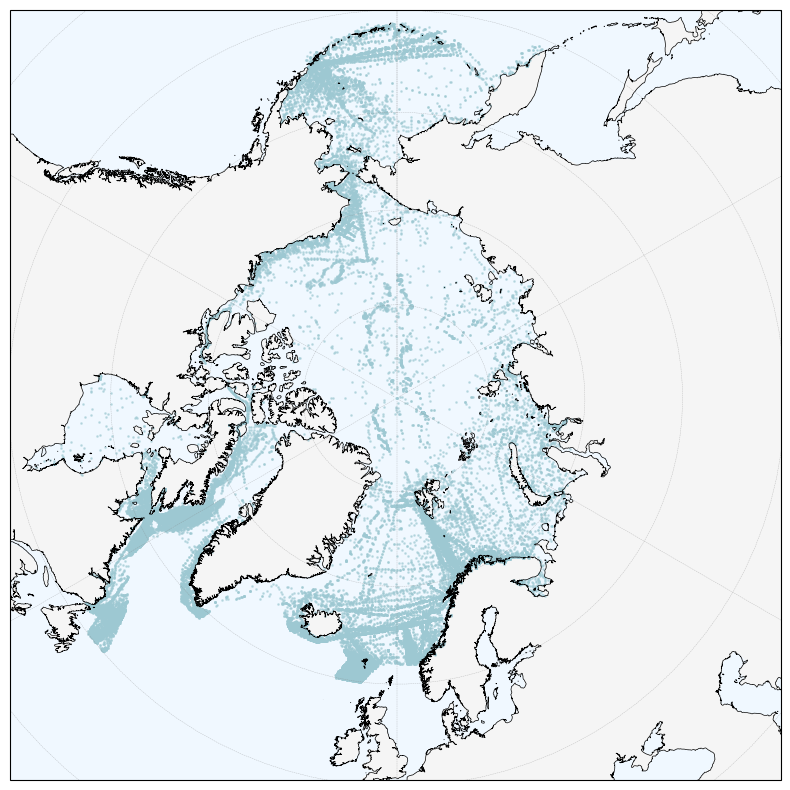

Plotted 63398 stations


In [15]:
# Load the dataset
file_path = "unique_stations_with_date.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Subset at station level

### Check that all station combinations have consistent 'keep' values

In [16]:
# Load the manual file
manual_df = pd.read_csv("unique_stations_with_status_manual.csv", low_memory=False)

# Group by the key columns and count unique 'keep' values per group
keep_check = manual_df.groupby(['decimalLatitude', 'decimalLongitude', 'dataset_id', 'samplingProtocol'])['keep'].nunique()

# Find groups with more than one unique 'keep' value
duplicates = keep_check[keep_check > 1]

if len(duplicates) > 0:
    print(f"⚠️ WARNING: Found {len(duplicates)} station combinations with multiple 'keep' values!")
    print("\nStation combinations with conflicting 'keep' values:")
    
    # Show the problematic stations with their different 'keep' values
    for idx in duplicates.index:
        lat, lon, dataset_id = idx
        station_data = manual_df[
            (manual_df['decimalLatitude'] == lat) & 
            (manual_df['decimalLongitude'] == lon) & 
            (manual_df['dataset_id'] == dataset_id)
        ]
        print(f"\nLat: {lat}, Lon: {lon}, Dataset: {dataset_id}")
        print(f"Keep values: {station_data['keep'].unique()}")
        print(station_data[['decimalLatitude', 'decimalLongitude', 'dataset_id', 'keep', 'bibliographicCitation']])
else:
    print(f"✓ All {len(keep_check)} station combinations have consistent 'keep' values.")

✓ All 29295 station combinations have consistent 'keep' values.


### Key in FUPR classification from manually edited file

In [17]:
# Merge station metadata with manual keep by full station keys
# Keys: decimalLatitude, decimalLongitude, dataset_id, samplingProtocol
# Strategy: Use rounded coordinates for matching (3 decimals ≈ 111m), preserve originals in output
csv_file = "unique_stations_with_date.csv"
manual_file = "unique_stations_with_status_manual.xlsx"
csv_data = pd.read_csv(csv_file)
manual_data = pd.read_excel(manual_file, engine='openpyxl')

# Normalize coordinates and dataset_id
for df_ in [csv_data, manual_data]:
    df_['decimalLatitude'] = pd.to_numeric(df_['decimalLatitude'], errors='coerce')
    df_['decimalLongitude'] = pd.to_numeric(df_['decimalLongitude'], errors='coerce')
    df_['dataset_id'] = df_['dataset_id'].astype(str).str.strip()

# Handle samplingProtocol separately and explicitly
csv_data['samplingProtocol'] = csv_data['samplingProtocol'].fillna('').astype(str).str.strip()
csv_data.loc[csv_data['samplingProtocol'] == 'nan', 'samplingProtocol'] = ''

manual_data['samplingProtocol'] = manual_data['samplingProtocol'].fillna('').astype(str).str.strip()
manual_data.loc[manual_data['samplingProtocol'] == 'nan', 'samplingProtocol'] = ''

# Create temporary rounded columns for matching (3 decimals ≈ 111m precision)
# Note: Original coordinates are preserved in output
csv_data['_lat_match'] = csv_data['decimalLatitude'].round(3)
csv_data['_lon_match'] = csv_data['decimalLongitude'].round(3)
manual_data['_lat_match'] = manual_data['decimalLatitude'].round(3)
manual_data['_lon_match'] = manual_data['decimalLongitude'].round(3)

# Ensure manual has one row per station key to avoid one-to-many expansion
match_keys = ['_lat_match', '_lon_match', 'dataset_id', 'samplingProtocol']
manual_keep = manual_data[match_keys + ['keep']].drop_duplicates(subset=match_keys)

# Merge on the rounded keys
merged_data = pd.merge(csv_data, manual_keep, on=match_keys, how='left')

# Drop temporary matching columns
merged_data = merged_data.drop(columns=['_lat_match', '_lon_match'])

output_file = "unique_stations_with_status.xlsx"
merged_data.to_excel(output_file, index=False)

# Report results
missing_count = merged_data['keep'].isna().sum()
print(f"Updated Excel saved as {output_file}")
print(f"Total rows: {len(merged_data)}")
print(f"Rows with keep: {len(merged_data) - missing_count}")
print(f"Rows missing keep: {missing_count}")

Updated Excel saved as unique_stations_with_status.xlsx
Total rows: 63398
Rows with keep: 63398
Rows missing keep: 0


In [18]:
# Load the dataset
file_path = "unique_stations_with_status.xlsx"
df = pd.read_excel(file_path, engine='openpyxl')
# Filter rows where the 'keep' column is empty or null
missing_keep = df[df['keep'].isna() | (df['keep'] == '')]
# Count the number of rows with missing 'keep' values
missing_count = len(missing_keep)

# Check if there are any missing values
if missing_count > 0:
    print(f"⚠️ WARNING: {missing_count} stations have missing 'keep' values!")
    print("\nStations with missing 'keep' values:")
    raise ValueError(f"Execution stopped: {missing_count} stations are missing 'keep' values. Please review and update the data before continuing.")
else:
    print(f"✓ All stations have 'keep' values assigned. Total stations checked: {len(df)}")

✓ All stations have 'keep' values assigned. Total stations checked: 63398


##### If some stations lack keep values, add them manually and then save the file as unique_stations_with_status_manual.csv and rerun the part above

## Subset stations according to FUPR

In [19]:
# Load the updated CSV file
input_file = "unique_stations_with_status.xlsx"
data = pd.read_excel(input_file, engine='openpyxl')
# Define the unique classes in the 'keep' column
classes = ['F', 'P', 'U', 'R']
# Loop through each class and create a subset
for cls in classes:
    subset = data[data['keep'] == cls]  # Filter rows where 'keep' equals the class
    output_file = f"unique_stations_with_status_{cls}.csv"  # Create a filename for the subset
    subset.to_csv(output_file, index=False)  # Save the subset to a new CSV file
    print(f"Saved subset for class '{cls}' as {output_file} with {len(subset)} stations.")
# Print the total count for each class
print("\nRecord counts per class:")
for cls in classes:
    count = len(data[data['keep'] == cls])
    print(f"Class '{cls}': {count} stations")

Saved subset for class 'F' as unique_stations_with_status_F.csv with 13172 stations.
Saved subset for class 'P' as unique_stations_with_status_P.csv with 8429 stations.
Saved subset for class 'U' as unique_stations_with_status_U.csv with 8 stations.
Saved subset for class 'R' as unique_stations_with_status_R.csv with 41789 stations.

Record counts per class:
Class 'F': 13172 stations
Class 'P': 8429 stations
Class 'U': 8 stations
Class 'R': 41789 stations


## Visualize subset coverage

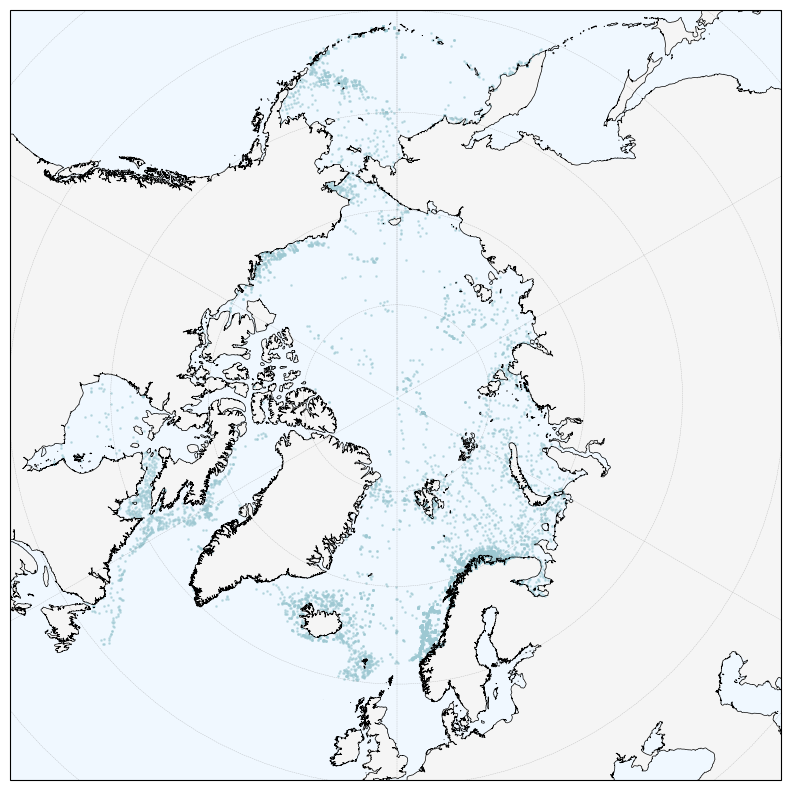

Plotted 13172 stations


In [20]:
# Load the dataset
file_path = "unique_stations_with_status_F.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

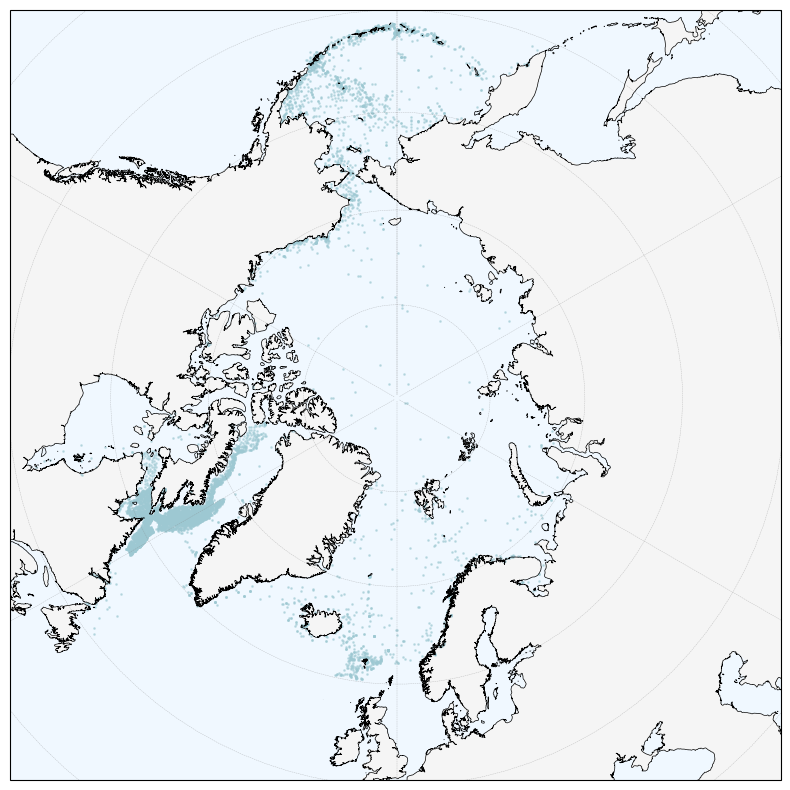

Plotted 8429 stations


In [21]:
# Load the dataset
file_path = "unique_stations_with_status_P.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

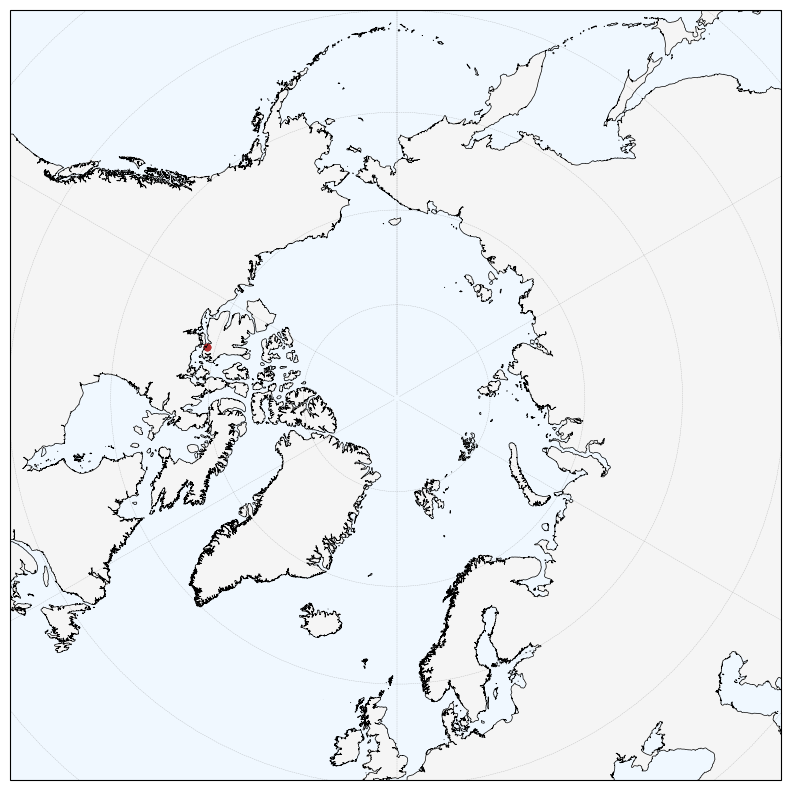

Plotted 8 stations


In [22]:
# Load the dataset
file_path = "unique_stations_with_status_U.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=20, color="#B12E2E", alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

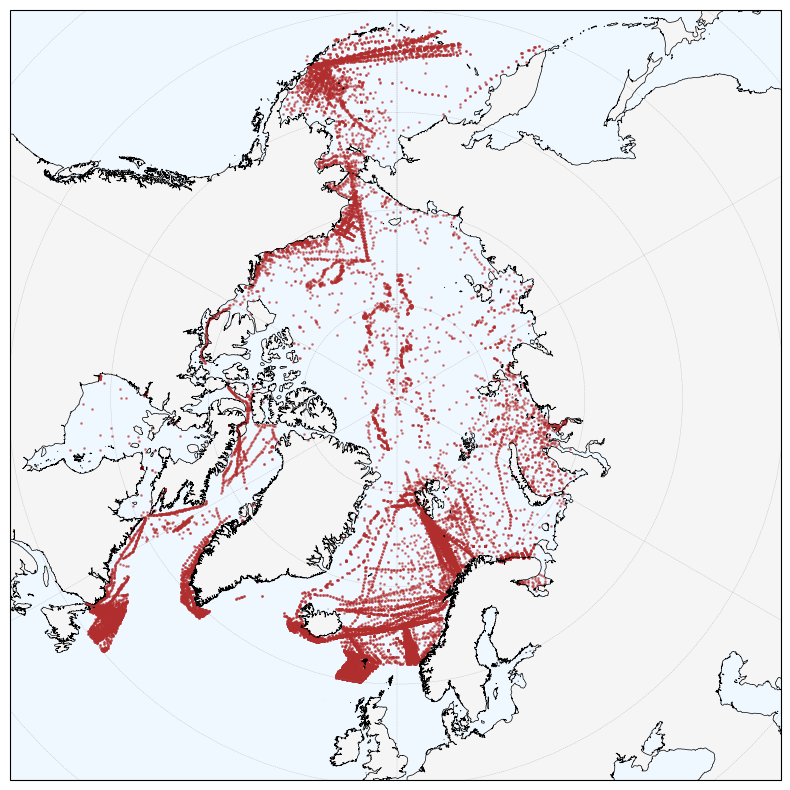

Plotted 41789 stations


In [23]:
# Load the dataset
file_path = "unique_stations_with_status_R.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color="#B12E2E", alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Subset at records level

In [24]:
# Load records and station-level keep classifications
records = pd.read_parquet("obis_filtered_dataset.parquet")
status = pd.read_excel("unique_stations_with_status.xlsx", engine='openpyxl')

# Normalize fields for matching
for df_ in (records, status):
    df_["decimalLatitude"] = pd.to_numeric(df_["decimalLatitude"], errors="coerce")
    df_["decimalLongitude"] = pd.to_numeric(df_["decimalLongitude"], errors="coerce")
    df_["dataset_id"] = df_["dataset_id"].astype(str).str.strip()
    df_["samplingProtocol"] = df_["samplingProtocol"].fillna("").astype(str).str.strip()
    df_.loc[df_["samplingProtocol"] == "nan", "samplingProtocol"] = ""
    df_["_lat_match"] = df_["decimalLatitude"].round(3)
    df_["_lon_match"] = df_["decimalLongitude"].round(3)

# Primary merge on rounded coords + dataset_id + samplingProtocol
primary_keys = ["_lat_match", "_lon_match", "dataset_id", "samplingProtocol"]
status_primary = status[primary_keys + ["keep"]].drop_duplicates(primary_keys)
merged = records.merge(status_primary, on=primary_keys, how="left")

# Secondary merge ignoring samplingProtocol for remaining unmatched
missing_mask = merged["keep"].isna() | (merged["keep"] == "")
if missing_mask.any():
    status_fallback = status[["_lat_match", "_lon_match", "dataset_id", "keep"]].drop_duplicates(
        ["_lat_match", "_lon_match", "dataset_id"]
    )
    fallback = (
        merged.loc[missing_mask, ["_lat_match", "_lon_match", "dataset_id"]]
        .merge(status_fallback, on=["_lat_match", "_lon_match", "dataset_id"], how="left")
        .get("keep")
    )
    merged.loc[missing_mask, "keep"] = fallback.values

# Drop helper columns
merged = merged.drop(columns=["_lat_match", "_lon_match"])

# Split into subsets
subsets = {}
for tag in ["F", "R", "U", "P"]:
    subsets[tag] = merged[merged["keep"] == tag]
    subsets[tag].to_parquet(f"obis_subset_{tag}.parquet", index=False)

unmatched = merged[merged["keep"].isna() | (merged["keep"] == "")]
unmatched.to_parquet("obis_subset_unmatched.parquet", index=False)

# Report counts
total = len(merged)
counts = {tag: len(df_) for tag, df_ in subsets.items()}
counts["unmatched"] = len(unmatched)

print(f"Total records: {total}")
for tag in ["F", "R", "U", "P", "unmatched"]:
    print(f"{tag}: {counts[tag]}")

if counts["unmatched"] > 0:
    print("⚠️ Warning: Some records remain unmatched. Please review 'obis_subset_unmatched.parquet'.")
else:
    print("✓ All records assigned to F/R/U/P; no unmatched records.")

Total records: 577634
F: 316235
R: 174430
U: 11748
P: 75221
unmatched: 0
✓ All records assigned to F/R/U/P; no unmatched records.


# Redistribute records based on taxa

### Obligate benthos

In [25]:
# Load the subsets
subset_F = pd.read_parquet("obis_subset_F.parquet")
subset_P = pd.read_parquet("obis_subset_P.parquet")
# Define the conditions (keys are integers) (Sipuncula order instead of phylum here)
phylum_keys = [146142, 558, 1806, 1818, 101061, 101063, 152391, 1803, 101060, 1276]
class_keys = [105, 104, 55, 1839, 883, 2094, 1302, 151365, 265044, 1341, 1340, 22388]
order_keys = [1360, 1102, 1609357, 106033, 1362, 1137, 1268, 2117, 468017]
family_keys = [1614, 2039, 106738, 106782, 118264, 118280, 106737, 22805, 110380, 368557, 118283, 118265, 127512]
genus_keys = [798733, 117233, 136256, 117235, 118429, 146534, 117117, 118420]
# Function to clean and convert columns to Int64
def clean_and_convert_to_int64(column):
    # Replace invalid values (non-numeric or NaN) with pd.NA
    column = pd.to_numeric(column, errors='coerce')
    # Convert to nullable integer type (Int64)
    return column.astype('Int64')
# Clean and convert the key columns in subset_P
subset_P['phylumid'] = clean_and_convert_to_int64(subset_P['phylumid'])
subset_P['classid'] = clean_and_convert_to_int64(subset_P['classid'])
subset_P['orderid'] = clean_and_convert_to_int64(subset_P['orderid'])
subset_P['familyid'] = clean_and_convert_to_int64(subset_P['familyid'])
subset_P['genusid'] = clean_and_convert_to_int64(subset_P['genusid'])
# Filter records from subset_P that match the conditions, handling missing values with .notna()
records_to_move = subset_P[
    (subset_P['phylumid'].notna() & subset_P['phylumid'].isin(phylum_keys)) |
    (subset_P['classid'].notna() & subset_P['classid'].isin(class_keys)) |
    (subset_P['orderid'].notna() & subset_P['orderid'].isin(order_keys)) |
    (subset_P['familyid'].notna() & subset_P['familyid'].isin(family_keys)) |
    (subset_P['genusid'].notna() & subset_P['genusid'].isin(genus_keys))
]
# Count the number of records to move
num_records_moved = records_to_move.shape[0]
# Remove the filtered records from subset_P
subset_P = subset_P[~(
    (subset_P['phylumid'].notna() & subset_P['phylumid'].isin(phylum_keys)) |
    (subset_P['classid'].notna() & subset_P['classid'].isin(class_keys)) |
    (subset_P['orderid'].notna() & subset_P['orderid'].isin(order_keys)) |
    (subset_P['familyid'].notna() & subset_P['familyid'].isin(family_keys)) |
    (subset_P['genusid'].notna() & subset_P['genusid'].isin(genus_keys))
)]
# Add the filtered records to subset_F
subset_F = pd.concat([subset_F, records_to_move])
# Save the updated subsets back to Parquet files
subset_F.to_parquet("obis_subset_F.parquet", index=False)
subset_P.to_parquet("obis_subset_P.parquet", index=False)
# Print the number of records moved
print(f"Records moved successfully! Number of records moved: {num_records_moved}")

Records moved successfully! Number of records moved: 32836


## Unique taxa lists with aphiaID

In [26]:
# Load the Parquet file
file_path = 'obis_subset_F.parquet'  
# Read the Parquet file
data = pd.read_parquet(file_path)
# Select the relevant columns
columns_to_extract = ['scientificName', 'phylum', 'class', 'order', 'family', 'genus', 'aphiaID']
data_subset = data[columns_to_extract]
# Drop duplicates based on 'aphiaID' and remove rows with missing 'aphiaID'
unique_data = data_subset.drop_duplicates(subset='aphiaID').dropna(subset=['aphiaID'])
# Count the number of unique records based on 'aphiaID'
unique_count = unique_data['aphiaID'].nunique()
# Save the unique entries to a CSV file
output_file = 'unique_taxa_F.csv'  # Specify the output file name
unique_data.to_csv(output_file, index=False)
# Print the count and confirmation message
print(f"Number of unique aphiaIDs: {unique_count}")
print(f"Unique records with taxonomy saved to {output_file}")

Number of unique aphiaIDs: 3489
Unique records with taxonomy saved to unique_taxa_F.csv


In [27]:
# Load the Parquet file
file_path = 'obis_subset_P.parquet'  
# Read the Parquet file
data = pd.read_parquet(file_path)
# Select the relevant columns
columns_to_extract = ['scientificName', 'phylum', 'class', 'order', 'family', 'genus', 'aphiaID']
data_subset = data[columns_to_extract]
# Drop duplicates based on 'aphiaID' and remove rows with missing 'aphiaID'
unique_data = data_subset.drop_duplicates(subset='aphiaID').dropna(subset=['aphiaID'])
# Count the number of unique records based on 'aphiaID'
unique_count = unique_data['aphiaID'].nunique()
# Save the unique entries to a CSV file
output_file = 'unique_taxa_P.csv'  # Specify the output file name
unique_data.to_csv(output_file, index=False)
# Print the count and confirmation message
print(f"Number of unique aphiaIDs: {unique_count}")
print(f"Unique records with taxonomy saved to {output_file}")

Number of unique aphiaIDs: 964
Unique records with taxonomy saved to unique_taxa_P.csv


## Check taxon overlap

In [28]:
# Load data
unique_taxa_F = pd.read_csv('unique_taxa_F.csv')
unique_taxa_P = pd.read_csv('unique_taxa_P.csv')
unique_taxa_orig = pd.read_excel('..\CB\original_updated.xlsx')

# F and P: use aphiaID
set_F = set(unique_taxa_F['aphiaID'].dropna().unique())
set_P = set(unique_taxa_P['aphiaID'].dropna().unique())
set_O = set(unique_taxa_orig['AcceptedAphiaId'].dropna().unique())

print(len(set_F))
print(len(set_P))
print(len(set_O))

3489
964
5109


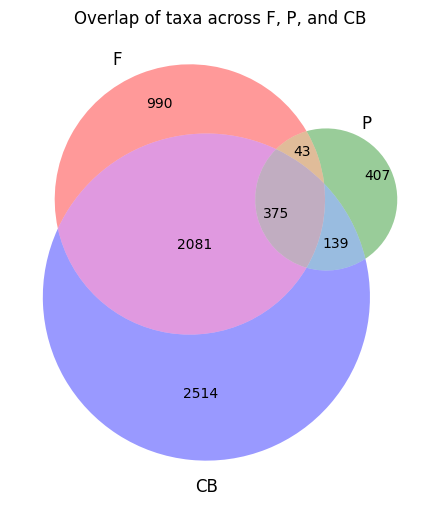

In [29]:
# This cell: create the 3-way Venn diagram for F, P, Original

plt.figure(figsize=(6, 6))
venn3([set_F, set_P, set_O], set_labels=('F', 'P', 'CB'))
plt.title('Overlap of taxa across F, P, and CB')
plt.show()

## Filter P using F and CB

In [30]:
# Load the CSV files
unique_taxa_P = pd.read_csv("unique_taxa_P.csv")
unique_taxa_F = pd.read_csv("unique_taxa_F.csv")
aphiaid_original = pd.read_excel("..\CB\original_updated.xlsx")
# Create sets of aphiaID from the other files
taxon_keys_F = set(unique_taxa_F['aphiaID'])
taxon_keys_gbif = set(aphiaid_original['AcceptedAphiaId'])
# Subset the records
P_benthic = unique_taxa_P[unique_taxa_P['aphiaID'].isin(taxon_keys_F | taxon_keys_gbif)]
P_non_benthic = unique_taxa_P[~unique_taxa_P['aphiaID'].isin(taxon_keys_F | taxon_keys_gbif)]
# Save the subsets to new CSV files
P_benthic.to_csv("P_benthic.csv", index=False)
P_non_benthic.to_csv("P_uncertain.csv", index=False)

print(len(P_benthic))
print(len(P_non_benthic))

557
407


In [31]:
# Load the CSV file
P_uncertain = pd.read_csv("P_uncertain.csv")
# Check the structure of the file to identify the relevant columns
print(P_uncertain.columns)
# Group by 'Phylum', 'Class', 'Order', 'Family', and 'Genus' and count the number of records
top_phyla = P_uncertain['phylum'].value_counts().head(10)
top_classes = P_uncertain['class'].value_counts().head(10)
top_orders = P_uncertain['order'].value_counts().head(10)
top_families = P_uncertain['family'].value_counts().head(10)
top_genera = P_uncertain['genus'].value_counts().head(10)
# Print the results
print("Top 10 Phyla:")
print(top_phyla)
print("\nTop 10 Classes:")
print(top_classes)
print("\nTop 10 Orders:")
print(top_orders)
print("\nTop 10 Families:")
print(top_families)
print("\nTop 10 Genera:")
print(top_genera)
# Save the results to CSV files if needed
top_phyla.to_csv("top_10_phyla.csv", header=["Count"])
top_classes.to_csv("top_10_classes.csv", header=["Count"])
top_orders.to_csv("top_10_orders.csv", header=["Count"])
top_families.to_csv("top_10_families.csv", header=["Count"])
top_genera.to_csv("top_10_genera.csv", header=["Count"])

Index(['scientificName', 'phylum', 'class', 'order', 'family', 'genus',
       'aphiaID'],
      dtype='str')
Top 10 Phyla:
phylum
Arthropoda         182
Mollusca           129
Cnidaria            45
Nematoda            30
Platyhelminthes     19
Chordata             2
Name: count, dtype: int64

Top 10 Classes:
class
Malacostraca      154
Gastropoda        112
Hydrozoa           45
Ostracoda          28
Chromadorea        24
Cephalopoda        17
Enoplea             6
Appendicularia      1
Name: count, dtype: int64

Top 10 Orders:
order
Amphipoda          50
Decapoda           48
Neogastropoda      47
Isopoda            30
Anthoathecata      22
Littorinimorpha    21
Mysida             16
Octopoda           14
Halocyprida        14
Leptothecata       14
Name: count, dtype: int64

Top 10 Families:
family
Buccinidae         27
Thoridae           14
Mysidae            14
Halocyprididae     12
Muricidae           9
Littorinidae        8
Pandeidae           8
Pleustidae          7
Stenothoida

In [32]:
# Load the CSV file
P_uncertain = pd.read_csv("P_benthic.csv")
# Check the structure of the file to identify the relevant columns
print(P_uncertain.columns)
# Group by 'Phylum', 'Class', 'Order', 'Family', and 'Genus' and count the number of records
top_phyla = P_uncertain['phylum'].value_counts().head(10)
top_classes = P_uncertain['class'].value_counts().head(10)
top_orders = P_uncertain['order'].value_counts().head(10)
top_families = P_uncertain['family'].value_counts().head(10)
top_genera = P_uncertain['genus'].value_counts().head(10)
# Print the results
print("Top 10 Phyla:")
print(top_phyla)
print("\nTop 10 Classes:")
print(top_classes)
print("\nTop 10 Orders:")
print(top_orders)
print("\nTop 10 Families:")
print(top_families)
print("\nTop 10 Genera:")
print(top_genera)
# Save the results to CSV files if needed
top_phyla.to_csv("top_10_phyla.csv", header=["Count"])
top_classes.to_csv("top_10_classes.csv", header=["Count"])
top_orders.to_csv("top_10_orders.csv", header=["Count"])
top_families.to_csv("top_10_families.csv", header=["Count"])
top_genera.to_csv("top_10_genera.csv", header=["Count"])

Index(['scientificName', 'phylum', 'class', 'order', 'family', 'genus',
       'aphiaID'],
      dtype='str')
Top 10 Phyla:
phylum
Arthropoda         391
Mollusca           128
Cnidaria            20
Nematoda             8
Annelida             3
Chordata             3
Platyhelminthes      2
Phoronida            2
Name: count, dtype: int64

Top 10 Classes:
class
Malacostraca    372
Gastropoda      116
Hydrozoa         19
Ostracoda        17
Cephalopoda      11
Chromadorea       7
Clitellata        2
Copepoda          1
Name: count, dtype: int64

Top 10 Orders:
order
Amphipoda          206
Isopoda             81
Neogastropoda       47
Decapoda            42
Littorinimorpha     30
Mysida              27
Tanaidacea          14
Trochida            12
Leptothecata        12
Cephalaspidea       10
Name: count, dtype: int64

Top 10 Families:
family
Mysidae            27
Buccinidae         26
Oedicerotidae      21
Ampeliscidae       19
Desmosomatidae     18
Tryphosidae        16
Uristidae      

## Merge unique taxa files for P benthic and F

In [33]:
# Load the files
file1 = pd.read_csv('P_benthic.csv')
file2 = pd.read_csv('unique_taxa_F.csv')
# Get the column names
columns_file1 = set(file1.columns)
columns_file2 = set(file2.columns)
# Compare the columns
if columns_file1 == columns_file2:
    print("The files have the same columns.")
else:
    print("The files have different columns.")
    print("Columns in P_benthic.csv but not in unique_taxa_F.csv:", columns_file1 - columns_file2)
    print("Columns in unique_taxa_F.csv but not in P_benthic.csv:", columns_file2 - columns_file1)

The files have the same columns.


In [34]:
# Concatenate the files
merged_file = pd.concat([file1, file2])
# Save the merged file
merged_file.to_csv('unique_taxa_keep.csv', index=False)
print("Files have been merged and saved as 'unique_taxa_keep.csv'.")

Files have been merged and saved as 'unique_taxa_keep.csv'.


# Filter records in obis_subset_P.parquet based on aphiaID in unique_taxa_keep

In [35]:
# Load the datasets
obis_data = pd.read_parquet('obis_subset_P.parquet')
unique_taxa = pd.read_csv('unique_taxa_keep.csv')
# Ensure taxonKey is the same data type in both datasets (integer)
obis_data['aphiaID'] = obis_data['aphiaID'].astype('Int64')  # Nullable integer type
unique_taxa['aphiaID'] = unique_taxa['aphiaID'].astype('Int64')  # Nullable integer type
# Filter records with matching aphiaID
records_keep = obis_data[obis_data['aphiaID'].isin(unique_taxa['aphiaID'])]
# Filter records without matching aphiaID
records_removed = obis_data[~obis_data['aphiaID'].isin(unique_taxa['aphiaID'])]
# Save the results as parquet files
records_keep.to_parquet('records_keep_P.parquet', index=False)
records_removed.to_parquet('records_removed_P.parquet', index=False)
print("Filtering complete. Files saved as 'records_keep_P.parquet' and 'records_removed_P.parquet'.")

Filtering complete. Files saved as 'records_keep_P.parquet' and 'records_removed_P.parquet'.


## Merge records for P benthic and F subsets

In [36]:
# Load the two Parquet files
file1 = "records_keep_P.parquet"
file2 = "obis_subset_F.parquet"
df1 = pd.read_parquet(file1)
df2 = pd.read_parquet(file2)
# Check if the columns are the same
if list(df1.columns) == list(df2.columns):
    print("Columns match! Proceeding with the merge.")
else:
    print("Columns do not match! Here are the differences:")
    print("Columns in file1 but not in file2:", set(df1.columns) - set(df2.columns))
    print("Columns in file2 but not in file1:", set(df2.columns) - set(df1.columns))
# Merge the two DataFrames (row-wise)
merged_df = pd.concat([df1, df2], ignore_index=True)
# Save the merged DataFrame to a new Parquet file
merged_df.to_parquet("obis_subset_merged_FP.parquet")
print("Files merged successfully and saved as 'obis_subset_merged_FP.parquet'.")

Columns match! Proceeding with the merge.
Files merged successfully and saved as 'obis_subset_merged_FP.parquet'.


## Stations in keep subset

In [37]:
# Load the records_keep.parquet file
records_keep = pd.read_parquet('obis_subset_merged_FP.parquet')
# Select the required columns
columns_to_keep = ['decimalLatitude', 'decimalLongitude', 'dataset_id', 'year', 'bibliographicCitation', 'depth', 'samplingProtocol']
filtered_data = records_keep[columns_to_keep]
# Drop duplicate rows based on decimalLatitude, decimalLongitude, dataset_id, bibliographicCitation and samplingProtocol
unique_combinations = filtered_data.drop_duplicates(subset=['decimalLatitude', 'decimalLongitude', 'dataset_id', 'samplingProtocol', 'bibliographicCitation'])
# Save the result as a CSV file
unique_combinations.to_csv('stations_keep.csv', index=False)
print("File with unique combinations saved as 'stations_keep.csv'.")

File with unique combinations saved as 'stations_keep.csv'.


# Visualize stations keep

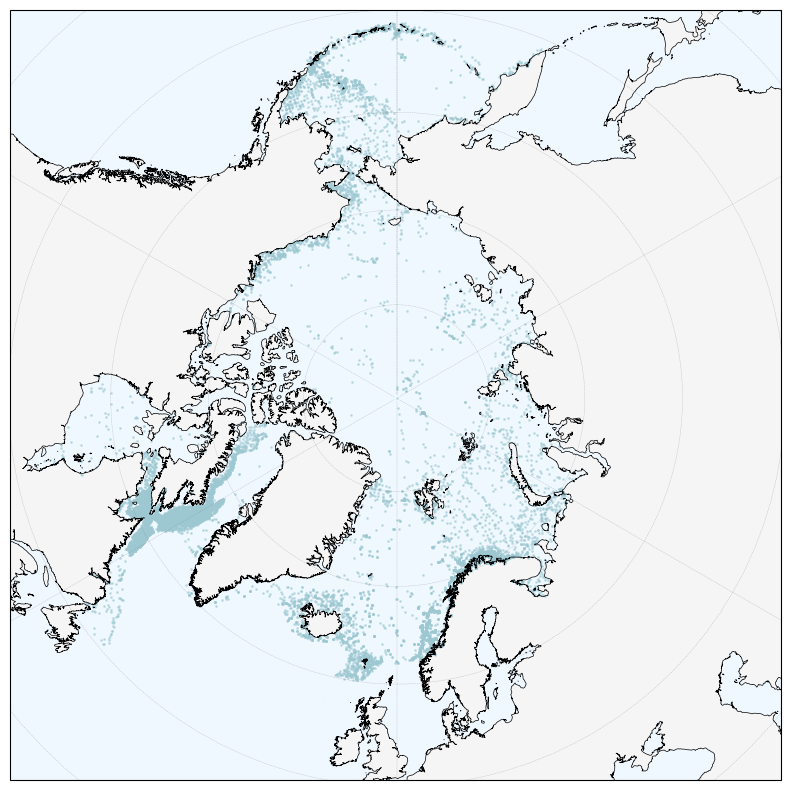

Plotted 19589 stations


In [38]:
# Load the dataset
file_path = "stations_keep.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

# Remove stations already in PANABIO

In [2]:
# Load the Biota sheet from the Excel file
biota_data = pd.read_excel('../CB/original.xlsx', sheet_name='Station')
# Select the required columns
columns_to_extract = ['StationID', 'DateStart', 'LatStart', 'LonStart']
cb_stations = biota_data[columns_to_extract].copy()  # Use .copy() to avoid the warning
# Create a new column 'Year' by extracting the year from the 'DateStart' column
cb_stations['Year'] = pd.to_datetime(cb_stations['DateStart']).dt.year
# Save the extracted data to a new Excel file
cb_stations.to_csv('CB_stations.csv', index=False)
print("Extracted data with 'Year' column saved as 'CB_stations.csv'.")

Extracted data with 'Year' column saved as 'CB_stations.csv'.


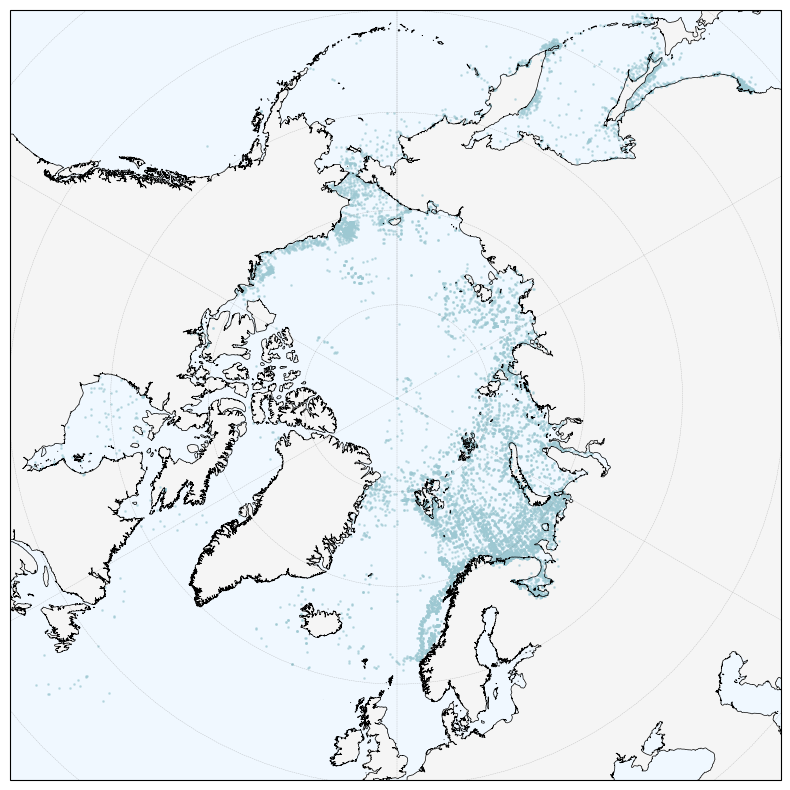

Plotted 12570 stations


In [3]:
# Load the dataset
file_path = "CB_stations.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['LonStart', 'LatStart']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['LonStart'].values, coords['LatStart'].values,
           s=1, color='#9DC8D2', alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

In [4]:
# Load the data from both files
cb_stations = pd.read_csv('CB_stations.csv')
stations_keep = pd.read_csv('stations_keep.csv')
# Normalize coordinates to 4 decimal places for consistency
cb_stations['LatStart'] = cb_stations['LatStart'].round(4)
cb_stations['LonStart'] = cb_stations['LonStart'].round(4)
stations_keep['decimalLatitude'] = stations_keep['decimalLatitude'].round(4)
stations_keep['decimalLongitude'] = stations_keep['decimalLongitude'].round(4)
# Count the number of stations before removing duplicates
stations_before = len(stations_keep)
# Standardize column names for comparison
cb_stations = cb_stations.rename(columns={'LatStart': 'decimalLatitude', 'LonStart': 'decimalLongitude', 'Year': 'year'})
# Perform a left merge to identify duplicates
merged = stations_keep.merge(
    cb_stations[['decimalLatitude', 'decimalLongitude', 'year']],
    on=['decimalLatitude', 'decimalLongitude', 'year'],
    how='left',
    indicator=True
)
# Filter out duplicates (stations that exist in CB_stations)
stations_keep_filtered = merged.query('_merge == "left_only"').drop(columns=['_merge'])
# Extract the filtered-out stations (duplicates)
filtered_out_stations = merged.query('_merge == "both"').drop(columns=['_merge'])
# Count the number of stations after removing duplicates
stations_after = len(stations_keep_filtered)
# Save the updated stations_keep file
stations_keep_filtered.to_csv('stations_keep_notCB.csv', index=False)
# Save the filtered-out stations to a separate file
filtered_out_stations.to_csv('stations_alreadyCB.csv', index=False)
# Print the results
print(f"Number of stations before removing duplicates: {stations_before}")
print(f"Number of stations after removing duplicates: {stations_after}")
print(f"Number of stations filtered out: {len(filtered_out_stations)}")

Number of stations before removing duplicates: 19589
Number of stations after removing duplicates: 19418
Number of stations filtered out: 187


Visualize removed stations

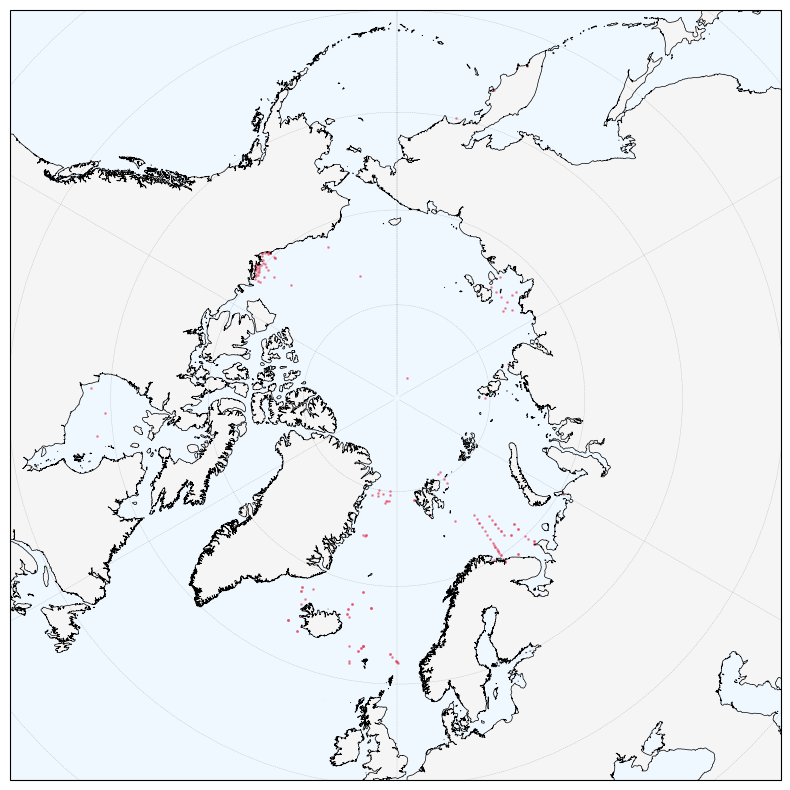

Plotted 187 stations


In [6]:
# Load the dataset
file_path = "stations_alreadyCB.csv"
df = pd.read_csv(file_path)
# Extract the coordinates
coords = df[['decimalLongitude', 'decimalLatitude']].dropna()  # Remove rows with missing coordinates
# Create the plot
plt.figure(figsize=(10, 10))
proj = ccrs.NorthPolarStereo()  # Use a North Polar Stereographic projection
ax = plt.axes(projection=proj)
# Set the extent to focus on the northern hemisphere
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
# Add map features
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')  # Land in white
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')  # Ocean in blue
ax.coastlines(resolution='10m', linewidth=0.5, color='black')  # Coastlines
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')  # Gridlines
# Plot the station points
ax.scatter(coords['decimalLongitude'].values, coords['decimalLatitude'].values,
           s=1, color="#E4455F", alpha=0.5, transform=ccrs.PlateCarree())
# Save the map as an image
plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
# Show the map
plt.show()
# Print the number of stations plotted
print(f'Plotted {len(coords)} stations')

Remove records belonging to PANABIO stations

In [7]:
# Load the data from both files
records_keep = pd.read_parquet('obis_subset_merged_FP.parquet')
stations_alreadyCB = pd.read_csv('stations_alreadyCB.csv')
# Convert coordinates to numeric (float) in both DataFrames
records_keep['decimalLatitude'] = pd.to_numeric(records_keep['decimalLatitude'], errors='coerce')
records_keep['decimalLongitude'] = pd.to_numeric(records_keep['decimalLongitude'], errors='coerce')
stations_alreadyCB['decimalLatitude'] = pd.to_numeric(stations_alreadyCB['decimalLatitude'], errors='coerce')
stations_alreadyCB['decimalLongitude'] = pd.to_numeric(stations_alreadyCB['decimalLongitude'], errors='coerce')
# Convert 'year' to integer in both DataFrames
records_keep['year'] = pd.to_numeric(records_keep['year'], errors='coerce').astype('Int64')
stations_alreadyCB['year'] = pd.to_numeric(stations_alreadyCB['year'], errors='coerce').astype('Int64')
# Normalize coordinates to 4 decimal places for consistency
records_keep['decimalLatitude'] = records_keep['decimalLatitude'].round(4)
records_keep['decimalLongitude'] = records_keep['decimalLongitude'].round(4)
stations_alreadyCB['decimalLatitude'] = stations_alreadyCB['decimalLatitude'].round(4)
stations_alreadyCB['decimalLongitude'] = stations_alreadyCB['decimalLongitude'].round(4)
# Select the relevant columns from stations_alreadyCB
stations_combinations = stations_alreadyCB[['decimalLatitude', 'decimalLongitude', 'year']].drop_duplicates()
# Perform an anti-join to remove matching rows
records_filtered = records_keep.merge(
    stations_combinations,
    on=['decimalLatitude', 'decimalLongitude', 'year'],
    how='left',
    indicator=True
).query('_merge == "left_only"').drop(columns=['_merge'])
# Save the filtered records to a new Parquet file
records_filtered.to_parquet('records_keep_notCB.parquet', index=False)
# Print the results
print(f"Number of records before filtering: {len(records_keep)}")
print(f"Number of records after filtering: {len(records_filtered)}")
print(f"Number of records removed: {len(records_keep) - len(records_filtered)}")

Number of records before filtering: 376480
Number of records after filtering: 373026
Number of records removed: 3454


In [8]:
# Load the Parquet file into a DataFrame
file_path = "records_keep_notCB.parquet"
df = pd.read_parquet(file_path)
# Check for duplicate rows
duplicates = df[df.duplicated()]
# Print the number of duplicate rows
print(f"Number of duplicate rows: {len(duplicates)}")
# If you want to drop duplicates and keep only unique rows:
df_unique = df.drop_duplicates()
# Save the unique rows back to a Parquet file (optional)
df_unique.to_parquet("records_keep_notCB.parquet", index=False)

Number of duplicate rows: 0


# Check mof content

In [12]:
file_path = "records_keep_notCB.parquet"
df = pd.read_parquet(file_path)
unique_id_count = df["id"].nunique(dropna=True)
print(f"Unique id count: {unique_id_count}")

Unique id count: 373026


In [13]:
# Load records to get valid ids
records_keep_notcb = pd.read_parquet(file_path)

# Filter MOF to ids present in records_keep_notCB
valid_ids = set(records_keep_notcb["id"].dropna())
mof_final = mof_df[mof_df["id"].isin(valid_ids)]

# Save filtered MOF
mof_final.to_parquet("mof_final_filter.parquet", index=False)

print(f"Filtered MOF rows: {len(mof_final)} saved to mof_final_filter.parquet")

Filtered MOF rows: 57807 saved to mof_final_filter.parquet


In [11]:
# Load the parquet file
mof_df = pd.read_parquet("mof_final_filter.parquet")

# Get unique measurementType + measurementUnit pairs and save to CSV
unique_measurement_pairs = (
    mof_df[["measurementType", "measurementUnit"]]
    .dropna(subset=["measurementType"])
    .drop_duplicates()
    .sort_values(["measurementType", "measurementUnit"], na_position="last")
    .reset_index(drop=True)
)

unique_measurement_pairs.to_csv(
    "measurementType_unique.csv", index=False, header=["measurementType", "measurementUnit"]
)

print(
    f"Saved {len(unique_measurement_pairs)} unique measurementType/measurementUnit pairs to measurementType_unique.csv"
)

Saved 136 unique measurementType/measurementUnit pairs to measurementType_unique.csv


# Check content in organismQuantityType and dynamicProperties

Checking dynamic properties

In [3]:
# Load the parquet file
mof_df = pd.read_parquet("records_keep_notCB.parquet")

# Get unique dynamicProperties entries (drop NaN) and save to CSV
unique_dynamicProperties = (
    mof_df["dynamicProperties"]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

unique_dynamicProperties.to_csv("dynamicProperties_unique.csv", index=False, header=["dynamicProperties"])

print(f"Saved {len(unique_dynamicProperties)} unique dynamicProperties entries to dynamicProperties_unique.csv")

Saved 5449 unique dynamicProperties entries to dynamicProperties_unique.csv


Checking organismQuantity

In [7]:
# Load the parquet file
mof_df = pd.read_parquet("records_keep_notCB.parquet")

# Get unique dynamicProperties entries (drop NaN) and save to CSV
unique_organismQuantityType = (
    mof_df["organismQuantityType"]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

print(unique_organismQuantityType.to_csv("organismQuantityType_unique.csv", index=False, header=["organismQuantityType"]))

print(f"Saved {len(unique_organismQuantityType)} unique organismQuantityType entries to organismQuantityType_unique.csv")

None
Saved 6 unique organismQuantityType entries to organismQuantityType_unique.csv


# individualCount

In [8]:
# Load the data
file_path = "records_keep_notCB.parquet"
df = pd.read_parquet(file_path)

# Ensure numeric for individualCount and organismQuantity
df["individualCount"] = pd.to_numeric(df["individualCount"], errors="coerce")
df["organismQuantity"] = pd.to_numeric(df["organismQuantity"], errors="coerce")

# Fill individualCount when empty and organismQuantityType matches
valid_types = {"abundance", "individuals", "number of individuals"}
mask = df["individualCount"].isna() & df["organismQuantityType"].isin(valid_types)
df.loc[mask, "individualCount"] = df.loc[mask, "organismQuantity"]

# Save updated data
df.to_parquet(file_path, index=False)

print(f"Updated individualCount for {mask.sum()} rows.")

Updated individualCount for 24602 rows.


In [12]:
# Load records and filtered MOF
records_df = pd.read_parquet("records_keep_notCB.parquet")
mof_filtered = pd.read_parquet("filtered_mof_combined.parquet")

# Filter relevant measurement types
target_types = {"ABUNDNR", "count", "individualCount", "taxon abundance"}
mof_subset = mof_filtered[mof_filtered["measurementType"].isin(target_types)].copy()

# Convert measurementValue to numeric
mof_subset["measurementValue"] = pd.to_numeric(mof_subset["measurementValue"], errors="coerce")

# Aggregate to one value per id (first non-null)
mof_values = (
    mof_subset.dropna(subset=["measurementValue"])
    .groupby("id", as_index=False)["measurementValue"]
    .first()
)

# Update individualCount where empty
records_df["individualCount"] = pd.to_numeric(records_df["individualCount"], errors="coerce")
missing_mask = records_df["individualCount"].isna()
records_df = records_df.merge(mof_values, on="id", how="left")
records_df.loc[missing_mask, "individualCount"] = records_df.loc[missing_mask, "measurementValue"]
records_df = records_df.drop(columns=["measurementValue"])

# Save result
records_df.to_parquet("obis_with_mof.parquet", index=False)
print(f"Saved updated records to obis_with_mof.parquet. Filled {missing_mask.sum()} rows (where available).")

Saved updated records to obis_with_mof.parquet. Filled 91578 rows (where available).
